# ACL Project Milestone 1

# Imports


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2a78d6", "#eb6834"])
pd.set_option("display.max_columns", 50)

DATA_DIR = "dataset/"
MISSING = r"\N"   # the placeholder this dataset uses for missing values

## 1. Data Cleaning & Auditing

### 1.1 Dataset Loading and Initial EDA

A first look at the data **before any cleaning**. We load every table twice:

- `raw`: exactly as in the files (`\N` stays as text). Used to count the problems.
- `data`: the same files, but with `\N` read as a missing value. Used to explore.

The CSV files themselves are never changed.

In [26]:
table_names = ["circuits", "constructors", "drivers", "seasons", "races", "status", "results",
               "qualifying", "sprint_results", "driver_standings", "constructor_standings",
               "constructor_results", "lap_times", "pit_stops"]

raw = {}
data = {}
for name in table_names:
    raw[name] = pd.read_csv(DATA_DIR + name + ".csv")
    data[name] = pd.read_csv(DATA_DIR + name + ".csv", na_values=MISSING)

pd.DataFrame({
    "rows": {name: len(df) for name, df in raw.items()},
    "columns": {name: df.shape[1] for name, df in raw.items()},
})

,rows,columns
circuits,77,9
constructors,212,5
drivers,861,9
seasons,75,2
races,1125,18
status,139,2
results,26759,18
qualifying,10494,9
sprint_results,360,16
driver_standings,34863,7


#### 1.1.1 First rows of the main tables

In [27]:
for name in ["results", "races", "qualifying"]:
    print(name)
    display(raw[name].head(3))

results


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.00,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.00,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.00,58,+8.163,5698779,41,5,1:28.090,216.719,1


races


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


qualifying


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079


- `results` is the main table: one row per driver per race. The target comes from `positionOrder`.
- `races` adds the year and circuit; `qualifying` adds the qualifying position and lap times (`q1`, `q2`, `q3`).
- `\N` is already visible in the first rows, and dates and lap times are stored as text.

#### 1.1.2 Hidden missing values (`\N`) and wrong data types

Missing values pandas finds in raw results: 0
\N values actually in raw results: 122887


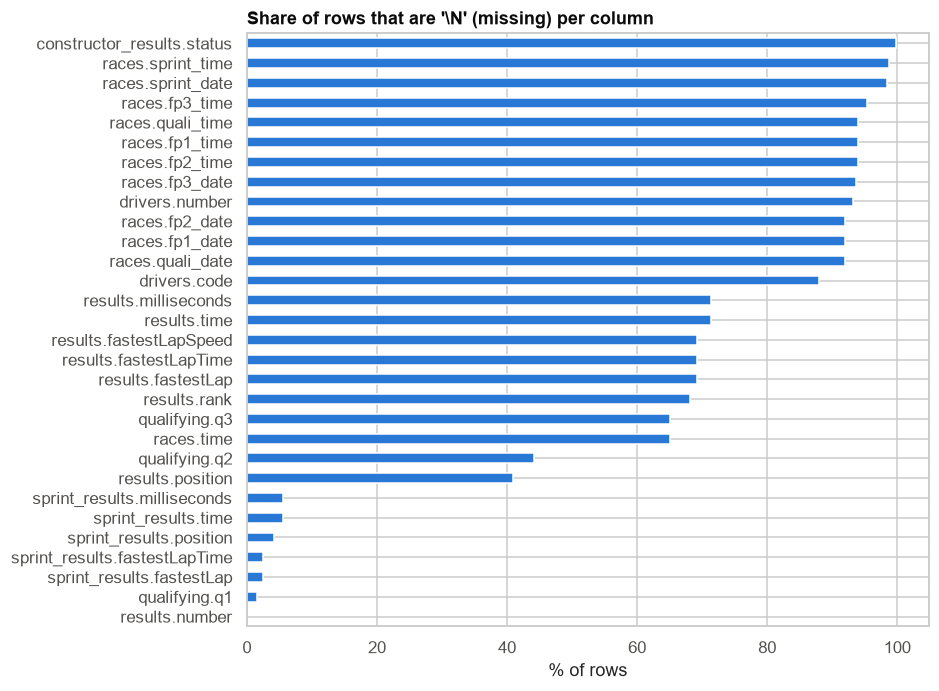

In [28]:
rows = []
for name, df in raw.items():
    for col in df.columns:
        count = (df[col].astype(str) == MISSING).sum()
        if count > 0:
            rows.append({"column": name + "." + col, "count": count, "percent": 100 * count / len(df)})
missing = pd.DataFrame(rows).sort_values("percent")

print("Missing values pandas finds in raw results:", raw["results"].isna().sum().sum())
print(r"\N values actually in raw results:", missing.loc[missing["column"].str.startswith("results."), "count"].sum())

missing.plot.barh(x="column", y="percent", figsize=(8, 7), legend=False)
plt.title(r"Share of rows that are '\N' (missing) per column")
plt.xlabel("% of rows")
plt.ylabel("")
plt.show()

In [29]:
# One '\N' is enough to turn a whole numeric column into text
pd.DataFrame({"raw dtype": raw["results"].dtypes, r"dtype with \N as missing": data["results"].dtypes})

,raw dtype,dtype with \N as missing
resultId,int64,int64
raceId,int64,int64
driverId,int64,int64
constructorId,int64,int64
number,str,float64
grid,int64,int64
position,str,float64
positionText,str,str
positionOrder,int64,int64
points,float64,float64


- pandas finds **0** missing values in raw `results`, but there are **122,887** `\N` values. The missing data is hidden.
- Because of `\N`, numeric columns like `position`, `milliseconds`, and `rank` are read as text. Reading `\N` as
  missing fixes this.
- Many columns are mostly empty (e.g. `constructor_results.status` 100%, practice-session dates in `races` over 90%).
- Dates (`races.date`, `drivers.dob`) and lap times (`q1`–`q3`, e.g. `"1:26.572"`) are still text.

**Next (1.2):** convert dates to dates and lap times to seconds, and drop the mostly-empty columns.

#### 1.1.3 Data coverage over time

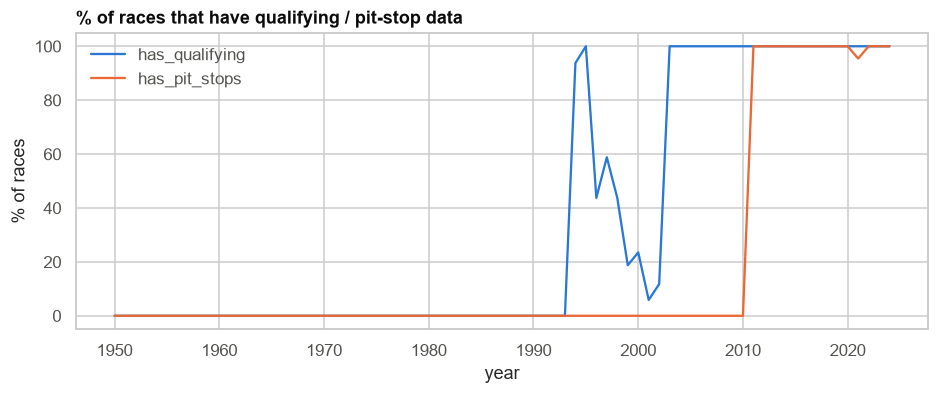

year,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004
has_qualifying,94.00,100.00,44.00,59.00,44.00,19.00,24.00,6.00,12.00,100.00,100.00


In [30]:
races = data["races"].copy()
races["has_qualifying"] = races["raceId"].isin(data["qualifying"]["raceId"])
races["has_pit_stops"] = races["raceId"].isin(data["pit_stops"]["raceId"])
coverage = races.groupby("year")[["has_qualifying", "has_pit_stops"]].mean() * 100

coverage.plot(figsize=(10, 3.5))
plt.title("% of races that have qualifying / pit-stop data")
plt.ylabel("% of races")
plt.show()

coverage.loc[1994:2004, ["has_qualifying"]].T.round(0)

- Qualifying data starts in **1994**, but between 1996 and 2002 only part of the races have it. It is complete from **2003**.
- Pit-stop data only exists from 2011.
- Since qualifying is one of our most important pre-race inputs, we will most likely model the seasons
  **2003–2024**. This is also a limitation to mention in the report.

#### 1.1.4 Duplicate rows: is (raceId, driverId) unique?

In [31]:
results = data["results"].merge(races[["raceId", "year"]], on="raceId")

duplicates = results[results.duplicated(["raceId", "driverId"], keep=False)]
print("Duplicated rows:", len(duplicates))
print("Driver-race pairs affected:", duplicates.groupby(["raceId", "driverId"]).ngroups)
print("Years:", duplicates["year"].min(), "to", duplicates["year"].max())

duplicates.sort_values(["raceId", "driverId"])[
    ["raceId", "year", "driverId", "constructorId", "grid", "positionOrder", "points"]].head(6)

Duplicated rows: 176
Driver-race pairs affected: 85
Years: 1950 to 1978


,raceId,year,driverId,constructorId,grid,positionOrder,points
13188,540,1978,229,54,0,26,0.00
13191,540,1978,229,57,0,29,0.00
17362,717,1964,373,172,1,7,0.00
24298,717,1964,373,172,1,12,0.00
17740,733,1962,465,172,0,22,0.00
17743,733,1962,465,97,0,25,0.00


- 85 driver-race pairs appear more than once (176 rows), all between 1950 and 1978.
- These are **shared drives**: in early F1 drivers could swap cars during a race, so one driver gets two result rows.
- **Next (1.4):** choose a rule for which row to keep, so each driver appears once per race.

#### 1.1.5 The target: podium finishes

Podium rate: 12.7%


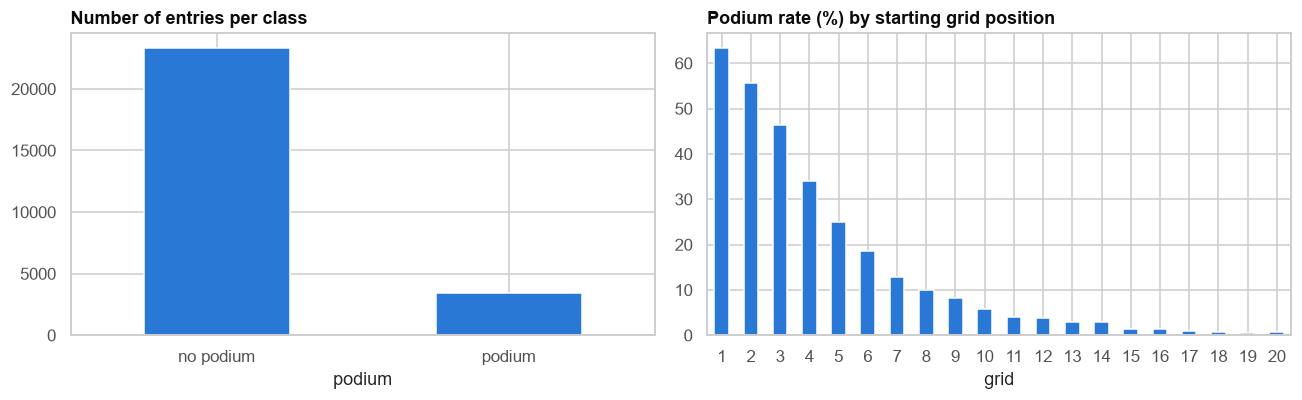

In [32]:
results["podium"] = results["positionOrder"] <= 3
print(f"Podium rate: {results['podium'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
results["podium"].map({True: "podium", False: "no podium"}).value_counts().plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Number of entries per class")

podium_by_grid = results[results["grid"].between(1, 20)].groupby("grid")["podium"].mean() * 100
podium_by_grid.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Podium rate (%) by starting grid position")
plt.tight_layout()
plt.show()

- Only **12.7%** of entries are podiums, so the classes are imbalanced. Accuracy would be misleading, which is
  why we will use PR-AUC and F1.
- The starting position matters a lot: starting from pole gives a 63% podium rate, P3 gives 46%, and past P10 it is
  below 5%. Grid and qualifying position will be our core features.

#### 1.1.6 Race outcomes and special values

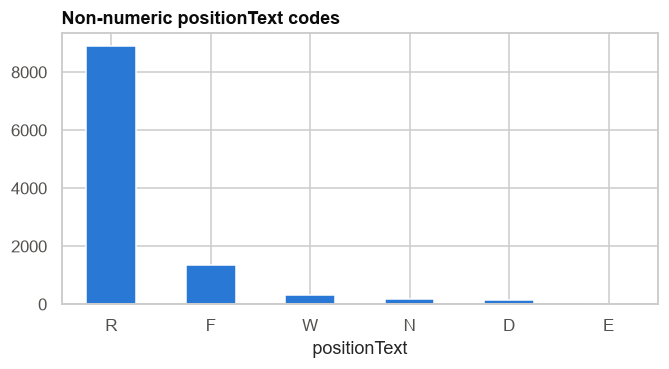

Entries with grid = 0: 1638
Podiums from grid = 0: 0
Grid differs from qualifying position: 23%


In [33]:
codes = results.loc[~results["positionText"].str.isnumeric(), "positionText"].value_counts()
codes.plot.bar(figsize=(7, 3.2), rot=0)
plt.title("Non-numeric positionText codes")
plt.show()

print("Entries with grid = 0:", (results["grid"] == 0).sum())
print("Podiums from grid = 0:", results.loc[results["grid"] == 0, "podium"].sum())

quali = data["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"})
grid_vs_quali = results.merge(quali, on=["raceId", "driverId"])
grid_vs_quali = grid_vs_quali[grid_vs_quali["grid"] > 0]
print(f"Grid differs from qualifying position: {(grid_vs_quali['grid'] != grid_vs_quali['quali_position']).mean():.0%}")

- `positionText` is not always a number: **R** = retired, **F** = failed to qualify, **W** = withdrawn,
  **N** = not classified, **D** = disqualified, **E** = excluded.
- **F** and **W** drivers never started the race, which is already known before the race, so they will be removed
  from the modelling table.
- `grid = 0` is not a real position (a non-qualifier, or a pit-lane start in modern races) and nobody ever reached
  the podium from it. It will be treated as missing plus a "pit-lane start" flag.
- The grid differs from the qualifying position for **23%** of entries (mostly penalties), so both are kept as
  separate features.

#### 1.1.7 Summary

| Finding | What we will do |
|---|---|
| `\N` hides missing values and turns numbers into text | Read `\N` as missing; convert dates and lap times (1.2) |
| Mostly-empty columns (practice dates, `constructor_results.status`) | Drop them (1.2) |
| 85 duplicated driver-race pairs (shared drives, 1950–1978) | Keep one row per driver per race (1.4) |
| Qualifying data complete only from 2003 | Model seasons 2003–2024; note it as a limitation |
| Only 12.7% podiums | Use PR-AUC / F1 and handle class imbalance (4) |
| Grid position strongly predicts podiums; grid ≠ qualifying position | Use both as features (3) |
| F/W entries never started; `grid = 0` is a special value | Remove F/W; treat `grid = 0` as missing + flag |
| Extreme pit-stop durations (red flags) | Cap or exclude if used |

### 1.2 Sentinel Handling and Semantic Typing

### 1.3 Primary-Key and Foreign-Key Validation

### 1.4 Driver-Race Grain and Shared-Drive Duplicate Handling

### 1.5 Post-Cleaning EDA and Cleaning Impact

## 2. Data-Engineering Questions

### 2.1 Front-Row Starts to Podiums by Circuit: Qualifying vs. Grid and the 2014 Hybrid Era

### 2.2 Home-Country Podium Advantage Controlling for Starting Position

### 2.3 Constructor Mechanical-Retirement Rates: 2014–2021 vs. 2022–2024

## 3. Feature Selection & Engineering

### 3.1 Pre-Race Prediction Cutoff and Leakage Audit

### 3.2 Unique Driver-Race Modeling Table and Podium Target

### 3.3 Leakage-Safe Historical Form, Standings, Grid, and Qualifying Features

### 3.4 EDA Evidence and Feature-Selection Justification

### 3.5 Training, Validation, and Test Split

### 3.6 Preprocessing, Encoding, and Effects on Feature Distributions

## 4. Predictive Modeling Task

### 4.1 Baseline and Primary/Secondary Evaluation Metrics

### 4.2 Statistical Model 1

### 4.3 Statistical Model 2

### 4.4 Shallow Neural Network

### 4.5 Hyperparameter and Threshold Selection on Training/Validation Data

### 4.6 Model Comparison: Training, Validation, and Unseen Test Performance

### 4.7 Evaluation Plots and Model Limitations

## 5. Experiments

### 5.1 Feature-Group Ablation

### 5.2 Preprocessing-Order Experiment 1

### 5.3 Preprocessing-Order Experiment 2

### 5.4 Experiment Comparison and Interpretation

## 6. Model Explainability (XAI)

### 6.1 Global Permutation Importance

### 6.2 Global SHAP Explanations

### 6.3 Local Prediction Explanation: LIME and/or SHAP

### 6.4 Interpretation and Non-Causal Limitations

## 7. Inference Function

### 7.1 Inference Pipeline

### 7.2 Demonstration with a Complete Record

### 7.3 Demonstration with a Partially Missing Record